**Unit 08 · Notebook 01**

# Audit quality and plan defensible repairs

**Learning objective:** Analyze completeness, validity, duplication, and timeliness.

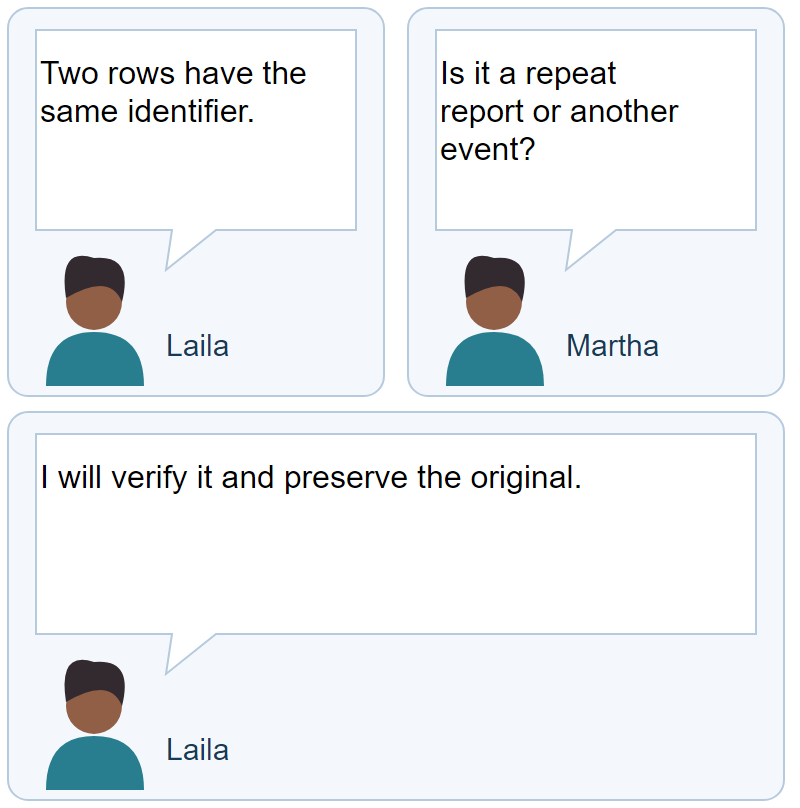

All records in this exercise are invented. Follow Laila's question, inspect the evidence, and check your decision.

## Quality is a question about fitness for use

The course defines data quality through accuracy and completeness and asks:
**Do the data accurately reflect reality, so that the data serve the intended purpose?**
Validation can expose a problem; a valid value is not proof of accuracy.

Audit this incoming extract using its stated dictionary:

- **Completeness:** count rows with a missing district.
- **Uniqueness:** count extra rows beyond the first occurrence of each `case_id`.
- **Validity:** count ages outside 0–120 years.
- **Timeliness:** count reports more than **2 days** after onset, using this training rule.

Run the next cell to inspect the rows and the Python audit function. You may call
`audit_quality(training_data)` in your own code cell to inspect its report. Enter
your counts, choose a repair approach, and select **Submit**.

For this training extract, the source review confirms Q02's district as **Port Loko**,
Q03's age as **18 years**, and the two identical Q01 rows as the **same report**.
The verified repair approach applies only those confirmations to a separate copy,
logs each original and replacement, and keeps the untouched incoming extract.
The late report remains late; correcting values cannot undo a reporting delay.

Do not replace a missing district with a guess, turn an impossible age into zero,
or silently delete a repeated ID. Check the source, retain the original values,
and log the reason and evidence for a correction. A repeated ID may represent a
repeat report or a separate event. Check what the rows describe before deciding what to do.


![Course visual: Laila and Martha: data source and quality context](../../readings/ucsf/assets/slide-previews/unit-2-068.jpg)

*Slide connection: Unit 2, Version 2, slide 68. Use this visual as you compare the data source, control, or evidence in the task.*


In [ ]:
# Run once to inspect the data and display the controls.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display
from html import escape
from collections import Counter
from datetime import date
import traitlets

class CourseChoices(widgets.VBox):
    value = traitlets.Tuple(default_value=())
    disabled = traitlets.Bool(False)
    def __init__(self, label, options):
        self.options = options
        self.boxes = [widgets.Checkbox(description=text, value=False, indent=False, layout=widgets.Layout(width="100%", height="auto")) for text, value in options]
        super().__init__([widgets.HTML("<b>" + escape(label) + "</b>"), *self.boxes], layout=widgets.Layout(width="100%"))
        for box in self.boxes:
            box.observe(self.collect, names="value")
        self.observe(self.lock, names="disabled")
    def collect(self, change):
        self.value = tuple(value for box, (text, value) in zip(self.boxes, self.options) if box.value)
    def lock(self, change):
        for box in self.boxes:
            box.disabled = self.disabled

def control_answer(control):
    if isinstance(control, CourseChoices):
        return list(control.value)
    if getattr(control, "course_integer", False):
        text = control.value.strip()
        return int(text) if text.isascii() and text.isdigit() else None
    return control.value

display(widgets.HTML("""<style>
.course-task-control { height: auto !important; margin-bottom: 0.75rem; gap: 0.25rem; }
.course-task-control .widget-checkbox { height: auto !important; min-height: 2rem; }
.course-task-control .widget-checkbox label { white-space: normal !important; height: auto !important; overflow: visible !important; text-overflow: clip !important; line-height: 1.5; align-items: flex-start; }
.course-task-control .widget-checkbox input { flex-shrink: 0; margin-top: 0.3rem; }
.course-task-control > label { width: auto !important; text-align: left; white-space: normal; line-height: 1.4; }
.course-task-control > select, .course-task-control > input { width: 100% !important; min-width: 0; max-width: 100%; flex: 0 0 auto !important; }
</style>"""))

training_data = {'sources': [{'id': 'case', 'row_represents': 'case', 'fields': ['case_id', 'district', 'onset_date', 'age'], 'access': 'district analyst'}, {'id': 'lab', 'row_represents': 'case', 'fields': ['case_id', 'specimen_date', 'result'], 'access': 'authorized laboratory extract'}, {'id': 'weekly', 'row_represents': 'district-week', 'fields': ['district', 'week', 'count'], 'access': 'public summary'}], 'required_fields': ['case_id', 'district', 'onset_date', 'result'], 'cases': [{'case_id': 'C01', 'district': 'Kambia', 'onset_date': '2021-10-18', 'age': 8, 'contact_label': 'Training contact A'}, {'case_id': 'C02', 'district': 'Kambia', 'onset_date': '2021-10-19', 'age': 12, 'contact_label': 'Training contact B'}, {'case_id': 'C03', 'district': 'Kambia', 'onset_date': '2021-10-20', 'age': 4, 'contact_label': 'Training contact C'}, {'case_id': 'C04', 'district': 'Port Loko', 'onset_date': '2021-10-20', 'age': 17, 'contact_label': 'Training contact D'}], 'lab': [{'case_id': 'C01', 'specimen_date': '2021-10-21', 'result': 'positive'}, {'case_id': 'C02', 'specimen_date': '2021-10-22', 'result': 'pending'}], 'role_fields': ['case_id', 'district', 'onset_date', 'age'], 'task_fields': ['case_id', 'district', 'onset_date'], 'release_minimum': 3, 'form': {'required': ['case_id', 'district', 'age'], 'age_min': 0, 'age_max': 120, 'districts': ['Kambia', 'Port Loko']}, 'submissions': [{'case_id': 'T01', 'district': 'Kambia', 'age': 8}, {'case_id': '', 'district': 'Kambia', 'age': 8}, {'case_id': 'T03', 'district': 'Kambia', 'age': 180}, {'case_id': 'T04', 'district': 'Other', 'age': 8}, {'case_id': 'T05', 'district': '', 'age': 8}, {'case_id': 'T06', 'district': 'Kambia', 'age': None}], 'dirty': [{'case_id': 'Q01', 'district': 'Kambia', 'age': 8, 'onset_date': '2021-10-18', 'report_date': '2021-10-19'}, {'case_id': 'Q01', 'district': 'Kambia', 'age': 8, 'onset_date': '2021-10-18', 'report_date': '2021-10-19'}, {'case_id': 'Q02', 'district': '', 'age': 12, 'onset_date': '2021-10-19', 'report_date': '2021-10-20'}, {'case_id': 'Q03', 'district': 'Port Loko', 'age': 180, 'onset_date': '2021-10-20', 'report_date': '2021-10-21'}, {'case_id': 'Q04', 'district': 'Kambia', 'age': 4, 'onset_date': '2021-10-18', 'report_date': '2021-10-25'}], 'timely_days': 2, 'verified_corrections': [{'case_id': 'Q02', 'field': 'district', 'value': 'Port Loko', 'evidence': 'Training register review: district confirmed'}, {'case_id': 'Q03', 'field': 'age', 'value': 18, 'evidence': 'Training register review: age confirmed as 18 years'}], 'verified_duplicate': {'case_id': 'Q01', 'evidence': 'Training source review: these identical rows are the same report'}}

def show_table(rows):
    if not rows:
        display(widgets.HTML("<p>No rows selected.</p>"))
        return
    names = list(rows[0])
    header = "".join("<th>" + escape(str(name)) + "</th>" for name in names)
    body = "".join("<tr>" + "".join("<td>" + escape(str(row.get(name, ""))) + "</td>" for name in names) + "</tr>" for row in rows)
    display(widgets.HTML('<div style="overflow-x:auto"><table><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table></div>'))


def audit_quality(data):
    rows = data["dirty"]
    ids = Counter(row["case_id"] for row in rows)
    return {"missing": sum(not row["district"] for row in rows),
            "duplicates": sum(count - 1 for count in ids.values()),
            "invalid": sum(not data["form"]["age_min"] <= row["age"] <= data["form"]["age_max"] for row in rows),
            "late": sum((date.fromisoformat(row["report_date"]) - date.fromisoformat(row["onset_date"])).days > data["timely_days"] for row in rows)}


def expected_answers(unit, data):
    """Recompute training expectations from source coverage and explicit rules."""
    if unit == 4:
        # Each selected source must add a required field; the aggregate lacks case IDs.
        required = set(data["required_fields"])
        selected = [s["id"] for s in data["sources"] if s["row_represents"] == "case" and required & set(s["fields"])]
        return {"sources": selected, "row_represents": "case"}
    if unit == 5:
        counts = Counter(row["district"] for row in data["cases"])
        return {"fields": sorted(set(data["task_fields"]) & set(data["role_fields"])),
                "suppress": sorted(k for k, v in counts.items() if v < data["release_minimum"])}
    if unit == 6:
        total = len(data["cases"])
        positive = sum(row["result"] == "positive" for row in data["lab"])
        # Claims 1 and 2 are numeric, claim 3 asserts causation without supporting evidence.
        claimed = {"all_positive": positive == total, "no_followup": all(row["result"] != "pending" for row in data["lab"])
                   and len(data["lab"]) == total, "water_caused": False}
        return {"claims": sorted(k for k, supported in claimed.items() if not supported), "review": "human_review"}
    if unit == 7:
        return {"required": data["form"]["required"], "age_max": data["form"]["age_max"],
                "district_control": "list"}
    if unit == 8:
        rows = data["dirty"]
        ids = Counter(row["case_id"] for row in rows)
        return {"missing": sum(not row["district"] for row in rows),
                "duplicates": sum(v - 1 for v in ids.values()),
                "invalid": sum(not data["form"]["age_min"] <= row["age"] <= data["form"]["age_max"] for row in rows),
                "late": sum((date.fromisoformat(row["report_date"]) - date.fromisoformat(row["onset_date"])).days > data["timely_days"] for row in rows),
                "repair": "verify_and_log"}
    raise ValueError(unit)


def evaluate_answer(unit, response, data):
    expected = expected_answers(unit, data)
    if not isinstance(response, dict) or any(response.get(k) is None or response.get(k) == [] for k in expected):
        return "incomplete"
    for key, value in expected.items():
        actual = response.get(key)
        if isinstance(value, list):
            if not isinstance(actual, (list, tuple)) or sorted(actual) != sorted(value):
                return "incorrect"
        elif actual != value:
            return "incorrect"
    return "correct"


def build_artifact(unit, response, data):
    """The learner's choices drive a real local transformation, including bad choices."""
    if unit == 4:
        selected = response["sources"]
        fields = set().union(*(set(s["fields"]) for s in data["sources"] if s["id"] in selected))
        missing = sorted(set(data["required_fields"]) - fields)
        print("Missing required fields: " + ", ".join(missing) if missing else "The selected data sources cover all four required fields.")
        if "case" in selected:
            lab = {row["case_id"]: row for row in data["lab"]} if "lab" in selected else {}
            return [{"case_id": row["case_id"], "district": row["district"], "onset_date": row["onset_date"],
                     "result": lab.get(row["case_id"], {}).get("result", "unknown")} for row in data["cases"]]
        return [{"district": key, "count": value} for key, value in Counter(row["district"] for row in data["cases"]).items()] if "weekly" in selected else []
    if unit == 5:
        allowed = set(response["fields"]) & set(data["role_fields"])
        denied = set(response["fields"]) - set(data["role_fields"])
        if denied:
            print("Role access denied for:", sorted(denied))
        internal = [{key: row[key] for key in response["fields"] if key in row and key in allowed} for row in data["cases"]] if allowed else []
        public = [{"district": key, "public_count": "withheld" if key in response["suppress"] else count}
                  for key, count in Counter(row["district"] for row in data["cases"]).items()]
        return {"Internal extract (invented records)": internal, "Public summary": public}
    if unit == 6:
        positive = sum(row["result"] == "positive" for row in data["lab"])
        pending = sum(row["result"] == "pending" for row in data["lab"])
        unmatched = len({row["case_id"] for row in data["cases"]} - {row["case_id"] for row in data["lab"]})
        return [{"measure": "Reported cases", "count": len(data["cases"])},
                {"measure": "Positive laboratory results", "count": positive},
                {"measure": "Pending laboratory results", "count": pending},
                {"measure": "Cases without a laboratory match", "count": unmatched}]
    if unit == 7:
        tested = []
        for i, row in enumerate(data["submissions"], 1):
            errors = [key + " required" for key in response["required"] if row.get(key) in (None, "")]
            age = row.get("age")
            if age not in (None, "") and (type(age) is not int or not data["form"]["age_min"] <= age <= response["age_max"]):
                errors.append("age must be whole years within range")
            if response["district_control"] == "list" and row.get("district") not in (None, "") and row["district"] not in data["form"]["districts"]:
                errors.append("district not recognized")
            tested.append({"submission": i, "accepted": not errors, "errors": "; ".join(errors)})
        return tested
    if unit == 8:
        actual = audit_quality(data)
        print("Computed audit:", actual)
        if response["repair"] != "verify_and_log":
            print("No changes applied: choose source verification with originals and a correction log.")
            return [dict(row) for row in data["dirty"]]
        cleaned, ledger, seen = [], [], {}
        for source in data["dirty"]:
            row = dict(source)
            if seen.get(row["case_id"]) == source and row["case_id"] == data["verified_duplicate"]["case_id"]:
                ledger.append({"case_id": row["case_id"], "field": "duplicate row", "before": dict(row),
                               "after": "earlier identical report retained", "evidence": data["verified_duplicate"]["evidence"]})
                continue
            seen[row["case_id"]] = dict(source)
            for change in data["verified_corrections"]:
                if change["case_id"] == row["case_id"]:
                    ledger.append({"case_id": row["case_id"], "field": change["field"], "before": row[change["field"]],
                                   "after": change["value"], "evidence": change["evidence"]})
                    row[change["field"]] = change["value"]
            cleaned.append(row)
        print("Audit after verified repairs:", audit_quality({**data, "dirty": cleaned}))
        return {"Verified correction log": ledger, "Cleaned copy": cleaned}
    return []

unit08_response = None
controls = {}
display(widgets.HTML('<p>Enter a whole number of zero or more. Leave a field blank if you have not answered it yet.</p>'))
show_table(training_data['dirty'])
controls['missing'] = widgets.Text(description='Missing district rows', value='', placeholder='Enter a whole number', style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['missing'].course_integer = True
controls['missing'].add_class('course-task-control')
display(controls['missing'])
controls['duplicates'] = widgets.Text(description='Extra duplicate-ID rows', value='', placeholder='Enter a whole number', style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['duplicates'].course_integer = True
controls['duplicates'].add_class('course-task-control')
display(controls['duplicates'])
controls['invalid'] = widgets.Text(description='Invalid age rows', value='', placeholder='Enter a whole number', style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['invalid'].course_integer = True
controls['invalid'].add_class('course-task-control')
display(controls['invalid'])
controls['late'] = widgets.Text(description='Late report rows', value='', placeholder='Enter a whole number', style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['late'].course_integer = True
controls['late'].add_class('course-task-control')
display(controls['late'])
controls['repair'] = widgets.Dropdown(description='Repair approach', options=[('Select an answer', None), ('Verify sources; preserve originals and log decisions', 'verify_and_log'), ('Guess missing values and overwrite originals', 'overwrite'), ('Delete every row with a repeated ID', 'delete_all')], value=None, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['repair'].add_class('course-task-control')
display(controls['repair'])


## Submit your decision

Run the next cell to display **Submit**, then select the button for feedback. Only an explicit submission records an attempt. Revise your choices and submit again to retry.

In [ ]:
# Run once to display Submit. Running this cell does not submit an attempt.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display, clear_output
from comm import create_comm
from html import escape

def _show_course_submission():
    prepare = '\nunit08_response = {key: control_answer(control) for key, control in controls.items()}\nexpected = expected_answers(8, training_data)\nlabels = {\'missing\': \'Missing district rows\', \'duplicates\': \'Extra duplicate-ID rows\', \'invalid\': \'Invalid age rows\', \'late\': \'Late report rows\', \'repair\': \'Repair approach\'}\noption_labels = {\'missing\': {}, \'duplicates\': {}, \'invalid\': {}, \'late\': {}, \'repair\': {\'verify_and_log\': \'Verify sources; preserve originals and log decisions\', \'overwrite\': \'Guess missing values and overwrite originals\', \'delete_all\': \'Delete every row with a repeated ID\'}}\nevidence = {\'missing\': \'Count rows with a blank district.\', \'duplicates\': \'Count extra copies of a case row, not all rows in a repeated pair.\', \'invalid\': \'Compare each age with the 0 to 120 training range.\', \'late\': \'Compare report date minus onset date with the two-day limit.\', \'repair\': \'Use the supplied source confirmations and retain a correction log.\'}\nfeedback_rows = []\nfor key, target in expected.items():\n    actual = unit08_response.get(key)\n    unanswered = actual is None or actual == []\n    correct = (sorted(actual) == sorted(target) if isinstance(target, list) and isinstance(actual, list) else actual == target)\n    shown = \', \'.join(option_labels[key].get(value, str(value)) for value in actual) if isinstance(actual, list) else option_labels[key].get(actual, str(actual))\n    feedback_rows.append({"Question": labels[key], "Submitted": ("Enter a whole number of zero or more" if getattr(controls[key], "course_integer", False) else "No choice selected") if unanswered else shown,\n                          "Feedback": "Answer needed" if unanswered else "Meets the stated rule" if correct else "Revise this decision",\n                          "Evidence to inspect": evidence[key]})\nshow_table(feedback_rows)\nresult = evaluate_answer(8, unit08_response, training_data)\nif result == "incomplete":\n    print("Complete every field before submitting again.")\nelse:\n    artifact = build_artifact(8, unit08_response, training_data)\n    if isinstance(artifact, dict):\n        for title, rows in artifact.items():\n            print(title)\n            show_table(rows)\n    else:\n        show_table(artifact)\n'
    fields = ()
    controls_for_task = dict(globals().get("controls", {}))
    submit = widgets.Button(description="Submit", button_style="info", disabled=True)
    feedback = widgets.HTML(value="Connecting to your learning record...")
    artifact_output = widgets.Output(layout=widgets.Layout(width="100%"))
    channel = create_comm(target_name="al.submit", data={"cell": '2'})
    def status(text):
        feedback.value = '<div role="status" aria-live="polite">' + text + '</div>'
    def receive(message):
        data = message["content"]["data"]
        if data.get("ready"):
            status("When your answer is ready, select Submit for feedback.")
        elif data.get("outcome") == "Incomplete":
            status("<b>Not complete yet.</b> Answer every part, then submit again. This attempt was recorded.")
        elif data.get("outcome") == "Correct":
            status("<b>Correct.</b> Your submitted answer follows the stated data and rules. This attempt was recorded.")
        elif data.get("outcome") == "Incorrect":
            status("<b>Not yet correct.</b> Compare your submitted answer with the displayed data and rules. Revise and submit again. This attempt was recorded.")
        else:
            status(escape(data.get("error", "Could not record this attempt. Please submit again.")))
        for control in controls_for_task.values():
            control.disabled = False
        submit.disabled = False
    channel.on_msg(receive)
    def send(_):
        if submit.disabled:
            return
        submit.disabled = True
        for control in controls_for_task.values():
            control.disabled = True
        status("Checking and recording your submitted answer...")
        try:
            with artifact_output:
                clear_output(wait=True)
                exec(prepare, globals())
                if fields:
                    rows = ''.join('<tr><th style="text-align:left">' + escape(name) + '</th><td>' +
                                   escape(str(globals().get(name))) + '</td></tr>' for name in fields)
                    display(widgets.HTML('<b>Submitted answer</b><table>' + rows + '</table>'))
            channel.send({"submit": True})
        except Exception as error:
            status("Could not prepare your answer: " + escape(str(error)) + ". Run the required cells and try again. No attempt was submitted.")
            for control in controls_for_task.values():
                control.disabled = False
            submit.disabled = False
    def edited(_):
        if not submit.disabled:
            status("Changes not submitted. Select Submit for feedback.")
    for control in controls_for_task.values():
        control.observe(edited, names="value")
    submit.on_click(send)
    display(submit, artifact_output, feedback)

_show_course_submission()


## Reflect on the decision

Run the next cell to write your reflections. Select **Record** to save them with your learner record in this browser. Reflections are unscored.

In [ ]:
# Run this cell to write and record your reflections.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from html import escape
from IPython.display import display
from comm import create_comm

def _reflection_section(section, questions):
    prompts = [question["prompt"] for question in questions]
    fields = []
    for number, prompt in enumerate(prompts, 1):
        field = widgets.Textarea(placeholder="Write your reflection here", rows=5,
                                 layout=widgets.Layout(width="100%"))
        fields.append(field)
        display(widgets.VBox([
            widgets.HTML(value=f"<strong>{number}. {escape(prompt)}</strong>"), field
        ], layout=widgets.Layout(width="100%", padding="0.5rem", margin="0 0 0.5rem 0")))
    button = widgets.Button(description="Record", button_style="info", disabled=True)
    status = widgets.HTML(value="Connecting to your browser learner record...")
    status.add_class("course-reflection-status")
    channel = create_comm(target_name="al.reflections", data={"section": section})
    def receive(message):
        data = message["content"]["data"]
        if "entries" in data:
            entries = data["entries"]
            restored = 0
            earlier = 0
            for question, field in zip(questions, fields):
                saved = next((entry for entry in reversed(entries) if
                    (entry.get("id") == question["id"] and entry.get("version") == question["version"]) or
                    (question["version"] == 1 and not entry.get("id") and entry["prompt"] in question["legacyPrompts"])), None)
                field.value = saved["answer"] if saved else ""
                restored += saved is not None
                earlier += any(entry.get("id") == question["id"] and entry.get("version") != question["version"] for entry in entries)
            status.value = "Recorded reflections restored." if restored else "Select Record to save in this browser."
            if earlier or any(entry.get("history") for entry in entries) or len(entries) > restored:
                status.value += " Earlier responses remain in My learning record and Download reflections. Review them before answering revised questions."
        elif data.get("saved"):
            status.value = "Recorded in this browser. Your reflections are unscored."
        else:
            status.value = escape(data.get("error", "Could not record. Please try again."))
        button.disabled = False
    channel.on_msg(receive)
    def record(_):
        button.disabled = True
        status.value = "Recording..."
        channel.send({"entries": [{**question, "answer": field.value}
                                  for question, field in zip(questions, fields)]})
    def edited(_):
        status.value = "Changes not recorded. Select Record to save."
    for field in fields:
        field.observe(edited, names="value")
    button.on_click(record)
    display(button, status)

_reflection_section('exercise:u08-quality-audit-repair', [{'id': 'q-271aecd92499', 'version': 1, 'prompt': 'Which source checks would you request before resolving the repeated identifier?', 'legacyPrompts': ['Which source checks would you request before resolving the repeated identifier?']}, {'id': 'q-e7ddce287be6', 'version': 1, 'prompt': 'What would your correction log contain, and how would unresolved errors affect the district summary?', 'legacyPrompts': ['What would your correction log contain, and how would unresolved errors affect the district summary?']}])


## Continue Laila's case

[Next notebook](u09-n01-dictionary-value-map.ipynb) · [Course start](u00-n00-start-here.ipynb)

Use the **Learning** panel to see what this attempt recorded and what it recommends. Your learning record keeps attempts and hints used.

## References

- FETP Version 2 Unit 2, slides 60–68; UCSF FETP Unit 2.2 and Case Study Assignment 4.
- [Unit 2 course slides (local PDF)](../../readings/ucsf/assets/unit-2-version-2-slides.pdf).
